# Regressionsbaum 

Trainset: (64, 5)
Testset: (14, 5)
Valset: (14, 5)
Encoded Train: (64, 97)
Encoded Val: (14, 97)
Encoded Test: (14, 97)
Aggregierte Daten:
      Category        Subcategory ProductLine                   Model  \
0  Accessories         Bike Racks           S     Hitch Rack - 4-Bike   
1  Accessories        Bike Stands           M  All-Purpose Bike Stand   
2  Accessories  Bottles and Cages           M    Mountain Bottle Cage   
3  Accessories  Bottles and Cages           R        Road Bottle Cage   
4  Accessories  Bottles and Cages           S            Water Bottle   

   OrderQuantity  
0           3166  
1            249  
2           2025  
3           1712  
4           6815  
Trainset: (64, 5)
Testset: (14, 5)
Valset: (14, 5)
Train: (64, 4) (64,)
Validation: (14, 4) (14,)
Test: (14, 4) (14,)

Anzahl der Features: 97
Feature-Namen: ['Category_Accessories', 'Category_Bikes', 'Category_Clothing', 'Category_Components', 'Subcategory_Bib-Shorts', 'Subcategory_Bike Stands', 'Subcatego

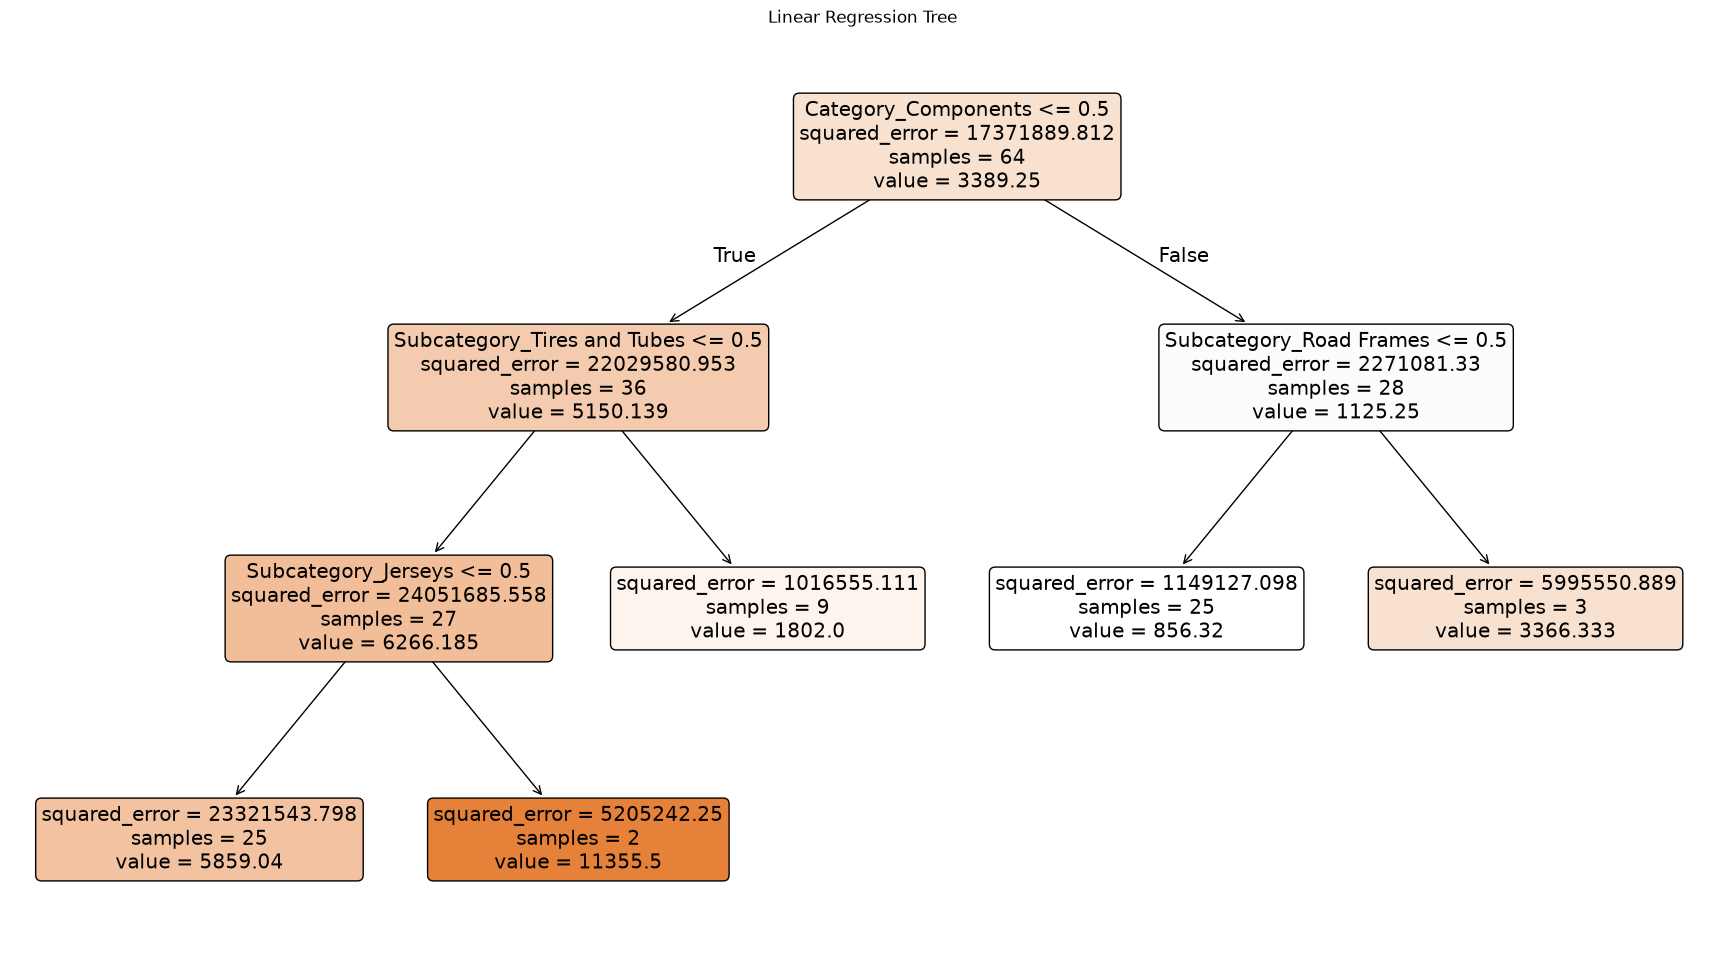

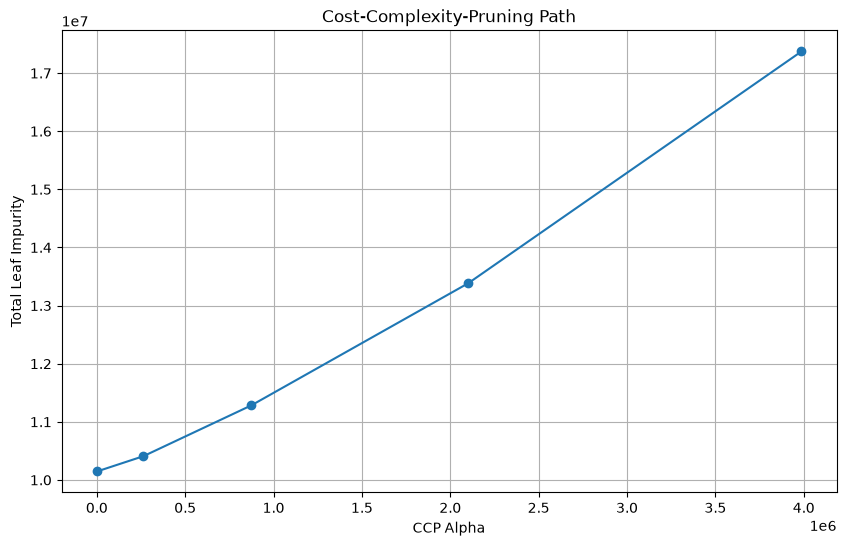

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

from vnw.defines.defines import (
    TESTSET_PATH,
    TRAINSET_PATH,
    VALSET_PATH,
)
from vnw.load_data.load_prepare_data import LoadPrepareData
from vnw.load_data.set_loader import SetLoader
from vnw.ml.dataset_loader import TrainTestValSplitter
from vnw.ml.feature_engineer import FeatureEngineer

df_raw = LoadPrepareData().load_and_prepare_data()

df = df_raw[
    [
        "Category",
        "Subcategory",
        "ProductLine",
        "Model",
        "OrderQuantity",
    ]
].copy()

df_agg = df.groupby(
    ["Category", "Subcategory", "ProductLine", "Model"], as_index=False
).agg({"OrderQuantity": "sum"})


TrainTestValSplitter(df_agg).get_splits_save_as_parquet()
set_loader = SetLoader(TRAINSET_PATH, TESTSET_PATH, VALSET_PATH)
trainset, testset, valset = set_loader.load_sets()


FEATURES = [
    "Category",
    "Subcategory",
    "ProductLine",
    "Model",
]

TARGET = "OrderQuantity"


X_train = trainset[FEATURES]
y_train = trainset[TARGET]

X_val = valset[FEATURES]
y_val = valset[TARGET]

X_test = testset[FEATURES]
y_test = testset[TARGET]


feature_engineer = FeatureEngineer(FEATURES)

X_train_enc = feature_engineer.fit_transform(X_train)
X_val_enc = feature_engineer.transform(X_val)
X_test_enc = feature_engineer.transform(X_test)

print("Encoded Train:", X_train_enc.shape)
print("Encoded Val:", X_val_enc.shape)
print("Encoded Test:", X_test_enc.shape)


# ============================================================
# 1. LINEAR REGRESSION TREE
# ============================================================


class LinearRegressionTree:
    def __init__(
        self,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        ccp_alpha=0.0,
    ):

        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_leaf_nodes = max_leaf_nodes
        self.min_impurity_decrease = min_impurity_decrease
        self.ccp_alpha = ccp_alpha

    # --------------------------------------------------------
    # Parameter validieren und in Python-Datentypen umwandeln
    # --------------------------------------------------------

    def _get_tree_parameters(self):

        return {
            "max_depth": (None if self.max_depth is None else int(self.max_depth)),
            "min_samples_split": int(self.min_samples_split),
            "min_samples_leaf": int(self.min_samples_leaf),
            "max_leaf_nodes": (
                None if self.max_leaf_nodes is None else int(self.max_leaf_nodes)
            ),
            "min_impurity_decrease": float(self.min_impurity_decrease),
            "ccp_alpha": float(self.ccp_alpha),
            "random_state": 42,
        }

    # --------------------------------------------------------
    # Modell trainieren
    # --------------------------------------------------------

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            self.feature_names_ = list(X.columns)
            X_array = X.to_numpy()
        else:
            X_array = np.asarray(X)
            self.feature_names_ = [f"x{i}" for i in range(X_array.shape[1])]

        y_array = np.asarray(y).ravel()

        self._X_fit_ = X_array.copy()
        self._y_fit_ = y_array.copy()

        # CART-Entscheidungsbaum
        self.tree_model_ = DecisionTreeRegressor(**self._get_tree_parameters())

        self.tree_model_.fit(X_array, y_array)

        # Blätter identifizieren
        leaf_ids = self.tree_model_.apply(X_array)

        self.leaf_models_ = {}

        # Für jedes Blatt ein lineares Regressionsmodell trainieren
        for leaf_id in np.unique(leaf_ids):
            mask = leaf_ids == leaf_id

            X_leaf = X_array[mask]
            y_leaf = y_array[mask]

            linear_model = LinearRegression()
            linear_model.fit(X_leaf, y_leaf)

            self.leaf_models_[leaf_id] = linear_model

        return self

    # --------------------------------------------------------
    # Vorhersagen
    # --------------------------------------------------------

    def predict(self, X):

        if isinstance(X, pd.DataFrame):
            X_array = X.to_numpy()
        else:
            X_array = np.asarray(X)

        leaf_ids = self.tree_model_.apply(X_array)

        predictions = np.zeros(len(X_array))

        for leaf_id in np.unique(leaf_ids):
            mask = leaf_ids == leaf_id

            linear_model = self.leaf_models_[leaf_id]

            predictions[mask] = linear_model.predict(X_array[mask])

        return predictions

    # --------------------------------------------------------
    # Modellkoeffizienten je Blatt anzeigen
    # --------------------------------------------------------

    def get_coefficients(self):

        rows = []

        for leaf_id, model in self.leaf_models_.items():
            row = {"Leaf": leaf_id, "Intercept": model.intercept_}

            for feature, coefficient in zip(
                self.feature_names_, model.coef_, strict=False
            ):
                row[feature] = coefficient

            rows.append(row)

        return pd.DataFrame(rows)

    # --------------------------------------------------------
    # Informationen über die Blätter
    # --------------------------------------------------------

    def get_leaf_models(self):

        leaf_ids = self.tree_model_.apply(self._X_fit_)

        rows = []

        for leaf_id, model in self.leaf_models_.items():
            mask = leaf_ids == leaf_id

            rows.append(
                {
                    "Leaf": leaf_id,
                    "Samples": int(mask.sum()),
                    "Intercept": model.intercept_,
                    "Coefficients": model.coef_,
                }
            )

        return pd.DataFrame(rows)

    # --------------------------------------------------------
    # Baumstruktur als Text
    # --------------------------------------------------------

    def get_tree_structure(self):

        return export_text(self.tree_model_, feature_names=self.feature_names_)

    # --------------------------------------------------------
    # Komplexität des Baums
    # --------------------------------------------------------

    def get_tree_info(self):

        tree = self.tree_model_.tree_

        return {
            "Number of nodes": tree.node_count,
            "Number of leaves": tree.n_leaves,
            "Maximum depth": self.tree_model_.get_depth(),
        }

    # --------------------------------------------------------
    # Cost-Complexity-Pruning-Pfad
    # --------------------------------------------------------

    def get_pruning_path(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_array = X.to_numpy()
        else:
            X_array = np.asarray(X)

        y_array = np.asarray(y).ravel()

        base_tree = DecisionTreeRegressor(
            max_depth=(None if self.max_depth is None else int(self.max_depth)),
            min_samples_split=int(self.min_samples_split),
            min_samples_leaf=int(self.min_samples_leaf),
            max_leaf_nodes=(
                None if self.max_leaf_nodes is None else int(self.max_leaf_nodes)
            ),
            min_impurity_decrease=float(self.min_impurity_decrease),
            random_state=42,
        )

        base_tree.fit(X_array, y_array)

        return base_tree.cost_complexity_pruning_path(X_array, y_array)

    # --------------------------------------------------------
    # Baum visualisieren
    # --------------------------------------------------------

    def plot_tree_structure(self, figsize=(20, 10)):

        plt.figure(figsize=figsize)

        plot_tree(
            self.tree_model_,
            feature_names=self.feature_names_,
            filled=True,
            rounded=True,
            impurity=True,
            proportion=False,
        )

        plt.title("Linear Regression Tree")
        plt.show()


# ============================================================
# 2. DATEN LADEN UND VORBEREITEN
# ============================================================

# Daten laden
df = LoadPrepareData().load_and_prepare_data()

# Benötigte Spalten auswählen
df = df[["Category", "Subcategory", "ProductLine", "Model", "OrderQuantity"]].copy()

# Aggregation auf Produktebene
df_agg = df.groupby(
    ["Category", "Subcategory", "ProductLine", "Model"], as_index=False
)["OrderQuantity"].sum()

print("Aggregierte Daten:")
print(df_agg.head())


# ============================================================
# 3. TRAIN-, VALIDATION- UND TESTDATEN ERSTELLEN
# ============================================================

FEATURES = ["Category", "Subcategory", "ProductLine", "Model"]

TARGET = "OrderQuantity"

# Splits erstellen und speichern
TrainTestValSplitter(df_agg).get_splits_save_as_parquet()

# Splits laden
loader = SetLoader(TRAINSET_PATH, TESTSET_PATH, VALSET_PATH)

trainset, testset, valset = loader.load_sets()

# Features und Target trennen
X_train = trainset[FEATURES]
y_train = trainset[TARGET]

X_val = valset[FEATURES]
y_val = valset[TARGET]

X_test = testset[FEATURES]
y_test = testset[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


# ============================================================
# 4. FEATURE ENGINEERING
# ============================================================

feature_engineer = FeatureEngineer(FEATURES)

X_train_enc = feature_engineer.fit_transform(X_train)

X_val_enc = feature_engineer.transform(X_val)

X_test_enc = feature_engineer.transform(X_test)

# DataFrames und NumPy-Arrays vereinheitlichen
if isinstance(X_train_enc, pd.DataFrame):
    feature_names = list(X_train_enc.columns)
else:
    feature_names = [f"x{i}" for i in range(np.asarray(X_train_enc).shape[1])]

print("\nAnzahl der Features:", len(feature_names))
print("Feature-Namen:", feature_names)


# ============================================================
# 5. GRID SEARCH
# ============================================================

param_grid = {
    # Pre-Pruning
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 5, 10],
    "max_leaf_nodes": [3, 5, 10],
    "min_impurity_decrease": [0.0],
    # Post-Pruning
    "ccp_alpha": [0.0, 0.001, 0.01, 0.1],
}


results = []

best_score = float("inf")
best_params = None
best_model = None

print("\nStarte Grid Search ...")

for params in ParameterGrid(param_grid):
    # --------------------------------------------------------
    # WICHTIG: Parameter in korrekte Python-Datentypen umwandeln
    # --------------------------------------------------------

    params = params.copy()

    integer_parameters = [
        "max_depth",
        "min_samples_split",
        "min_samples_leaf",
        "max_leaf_nodes",
    ]

    float_parameters = ["min_impurity_decrease", "ccp_alpha"]

    for parameter in integer_parameters:
        if params[parameter] is not None:
            params[parameter] = int(params[parameter])

    for parameter in float_parameters:
        params[parameter] = float(params[parameter])

    # Modell trainieren
    model = LinearRegressionTree(**params)

    model.fit(X_train_enc, y_train)

    # Validierung
    y_val_pred = model.predict(X_val_enc)

    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

    val_mae = mean_absolute_error(y_val, y_val_pred)

    val_r2 = r2_score(y_val, y_val_pred)

    results.append(
        {
            **params,
            "RMSE": val_rmse,
            "MAE": val_mae,
            "R2": val_r2,
            "Number of Leaves": model.tree_model_.get_n_leaves(),
            "Tree Depth": model.tree_model_.get_depth(),
        }
    )

    # Bestes Modell anhand des RMSE auswählen
    if val_rmse < best_score:
        best_score = val_rmse
        best_params = params.copy()
        best_model = model

    print(
        f"RMSE: {val_rmse:.4f} | "
        f"Depth: {model.tree_model_.get_depth()} | "
        f"Leaves: {model.tree_model_.get_n_leaves()}"
    )


# ============================================================
# 6. GRID-SEARCH-ERGEBNISSE
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

print("\nBeste Grid-Search-Ergebnisse:")
print(results_df.head(10))

print("\nBeste Parameter:")
print(best_params)

print("\nBester Validation-RMSE:")
print(best_score)


# ============================================================
# 7. BESTES MODELL ERNEUT ERSTELLEN
# ============================================================

# Parameter erneut absichern
best_params = best_params.copy()

best_params["max_depth"] = int(best_params["max_depth"])
best_params["min_samples_split"] = int(best_params["min_samples_split"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])

best_params["max_leaf_nodes"] = (
    None
    if best_params["max_leaf_nodes"] is None
    else int(best_params["max_leaf_nodes"])
)

best_params["min_impurity_decrease"] = float(best_params["min_impurity_decrease"])

best_params["ccp_alpha"] = float(best_params["ccp_alpha"])

print("\nDatentypen der besten Parameter:")
print({key: type(value) for key, value in best_params.items()})

best_model = LinearRegressionTree(**best_params)

best_model.fit(X_train_enc, y_train)


# ============================================================
# 8. TESTDATEN EVALUIEREN
# ============================================================

y_test_pred = best_model.predict(X_test_enc)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

test_mae = mean_absolute_error(y_test, y_test_pred)

test_r2 = r2_score(y_test, y_test_pred)

print("\nTESTERGEBNISSE")
print("-----------------------------")
print(f"RMSE: {test_rmse:.4f}")
print(f"MAE:  {test_mae:.4f}")
print(f"R²:   {test_r2:.4f}")


# ============================================================
# 9. BAUMSTRUKTUR
# ============================================================

print("\nBAUMSTRUKTUR")
print("-----------------------------")

print(best_model.get_tree_structure())


# ============================================================
# 10. BAUMINFORMATIONEN
# ============================================================

print("\nBAUMINFORMATIONEN")
print("-----------------------------")

tree_info = best_model.get_tree_info()

for key, value in tree_info.items():
    print(f"{key}: {value}")


# ============================================================
# 11. LINEARE KOEFFIZIENTEN JE BLATT
# ============================================================

print("\nLINEARE KOEFFIZIENTEN")
print("-----------------------------")

coefficients_df = best_model.get_coefficients()

print(coefficients_df)


# ============================================================
# 12. INFORMATIONEN ÜBER DIE BLÄTTER
# ============================================================

print("\nBLATTINFORMATIONEN")
print("-----------------------------")

leaf_info_df = best_model.get_leaf_models()

print(leaf_info_df)


# ============================================================
# 13. BAUM VISUALISIEREN
# ============================================================

best_model.plot_tree_structure(figsize=(22, 12))


# ============================================================
# 14. COST-COMPLEXITY-PRUNING-PFAD
# ============================================================

pruning_path = best_model.get_pruning_path(X_train_enc, y_train)

ccp_alphas = pruning_path.ccp_alphas
impurities = pruning_path.impurities

plt.figure(figsize=(10, 6))

plt.plot(ccp_alphas, impurities, marker="o")

plt.xlabel("CCP Alpha")
plt.ylabel("Total Leaf Impurity")
plt.title("Cost-Complexity-Pruning Path")
plt.grid(True)

plt.show()

In [37]:
# Neues Produkt
new_product = pd.DataFrame(
    {
        "Category": ["Bikes"],
        "ProductLine": ["R"],
        "Subcategory": ["Road Bikes"],
        "Model": ["Road-150"],
    }
)

# One-Hot-Encoding
new_product_enc = feature_engineer.transform(new_product)

# Zugehöriges Blatt bestimmen
new_product_array = np.asarray(new_product_enc)

leaf_id = best_model.tree_model_.apply(new_product_array)[0]

# Lineares Modell des ausgewählten Blattes
linear_model = best_model.leaf_models_[leaf_id]

# Koeffizienten auslesen
coefficients = linear_model.coef_
intercept = linear_model.intercept_

# Tatsächlich aktive Features und deren Beiträge
contributions = pd.DataFrame(
    {
        "Feature": feature_names,
        "Featurewert": new_product_array[0],
        "Koeffizient": coefficients,
    }
)

contributions["Beitrag"] = contributions["Featurewert"] * contributions["Koeffizient"]

active_features = contributions[contributions["Featurewert"] != 0]

print("Ausgewähltes Blatt:", leaf_id)
print("Intercept:", intercept)

print("\nAktive Koeffizienten:")
print(active_features.to_string(index=False))

print("\nFinale Berechnung:")
print(f"{intercept:.4f} + {active_features['Beitrag'].sum():.4f}")

# Finale Prognose
prediction = best_model.predict(new_product_enc)[0]

print("\nRoad-Racer Absatzprognose:")
print(f"{prediction:.2f} Stück")

Ausgewähltes Blatt: 5
Intercept: 5411.741139328011

Aktive Koeffizienten:
               Feature  Featurewert  Koeffizient      Beitrag
        Category_Bikes          1.0  1101.304720  1101.304720
Subcategory_Road Bikes          1.0   535.442319   535.442319
         ProductLine_R          1.0   -20.061898   -20.061898
        Model_Road-150          1.0 -4376.426280 -4376.426280

Finale Berechnung:
5411.7411 + -2759.7411

Road-Racer Absatzprognose:
2652.00 Stück
